In [63]:
import pandas as pd
import os
import re
import spacy
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns
import pyLDAvis
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import LatentDirichletAllocation

In [2]:
#Question 3.1 - Loading the corpus folder and its text files into Jupyter

path = "research_corpus"
articles = []

for filename in os.listdir(path):
    if filename.endswith(".txt"):
        file_path = os.path.join(path, filename)

        with open(file_path, "r", encoding="utf-8") as file:
            content = file.read()

        articles.append({
            "Article": filename,
            "Content": content
        })

I used os.listdir in order to retrieve all the files within the research_corpus folder. And I used endswith(".txt") to confirm I only read the text files.

In [3]:
df = pd.DataFrame(articles)
display(df)
print("Total Articles:", len(df))

,Article,Content
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...


Total Articles: 5


In [10]:
#Question 3.2) Preprocessing each article using state of the art techniques

nlp = spacy.load("en_core_web_sm")

def preprocess_text(text):

    text = text.lower() #For lower-casing the articles contents

    text = unicodedata.normalize("NFKC", text) #Unicode is for standardising characters ie. cleaning, analysis before model forming

    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text) #These codes are for removing HTML tags and URLs links

    text = re.sub(r"\s+", " ", text).strip() #For removing extra white spaces and any line breaks

    doc = nlp(text)
    tokens = [token.lemma_ for token in doc
                if not token.is_punct and not token.is_space] #Tokens will split text into individual tokens and lemmetization will convert words into 
                                                              #their base form ie. "running" will convert to "run"

    return " ".join(tokens)

In [11]:
#Now to take the preprocessing steps above and apply it to the 5 articles

df["Processed_Content"] = df["Content"].apply(preprocess_text)

display(df)

,Article,Content,Processed_Content
0,research_1.txt,The purposes of this article are to position m...,the purpose of this article be to position mix...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit...",now I see it now I do n’t researcher ’s positi...
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...,developmental research study of instructional ...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...,abstract cronbach ’s alpha be a statistic comm...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...,denzin ’s paradigm shift revisit triangulation...


Each of the 5 research articles were individually preprocessed using several text denosing techniques. The techniques include lowercasing, unicode normalisation, HTL and URL removal, and whitespace removal. Additionally, spaCy librabry was used for tokenization and lemmatization in order to standardise the text of the articles.

In [14]:
#Question 3.3) I have chosen to use TF-IDF

#The question only asks for the first research article, so only research_1.txt will be used
article = df.loc[
    df["Article"] == "research_1.txt", "Content" #Notice I am using the original "Content" and not the preprocessed one
].iloc[0]                                        #as extractive summarization needs to preserve complete, readable sentences

doc = nlp(article)
sentences = [sent.text.strip() for sent in doc.sents
             if len(sent.text.split()) >= 5] #SpaCy is used to split the article into sentences

The reason why I am using the original content and not the preprocess content is because in order to make use of summarization, the sentences need to be complete. If not it can lead to errors as lemmetization changes words into their base form.

In [28]:
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(sentences)
random_state=42

scores = tfidf_matrix.sum(axis=1).A1

top_sentences = scores.argsort()[-5:] #scores.argsort will return the 5 sentences with the highest TF-IDF scores
top_sentences = sorted(top_sentences) #maintains the original sequence if the article

summary = " ".join(sentences[i] for i in top_sentences)

print("Summary of Research_1.txt:\n")
print(summary)

Summary of Research_1.txt:

Reflexivity has been increasingly recognized as a crucial strategy in the process of generating knowledge by means of qualitative research
(Ahmed Dunya et al., 2011; Blaxter et al., 2006; D’Cruz et al., 2007; Gerstl-Pepin
and Patrizion, 2009; Hammersley and Atkinson, 2002; Horsburgh, 2003; Koch and
Harrington, 1998).For example, the journal Forum: Qualitative Research dedicated a
full issue (May 2003) to subjectivity and reflexivity in qualitative research, and there
Corresponding author:
Roni Berger, School of Social Work, Adelphi University, 1 South Avenue, Garden City, NY 11530, USA. Relevant researcher’s positioning include personal characteristics, such as gender,
race, affiliation, age, sexual orientation, immigration status, personal experiences, linguistic tradition, beliefs, biases, preferences, theoretical, political and ideological stances,
and emotional responses to participant (Bradbury-Jones, 2007; Finlay, 2000; Hamzeh
and Oliver, 2010; Horsbur

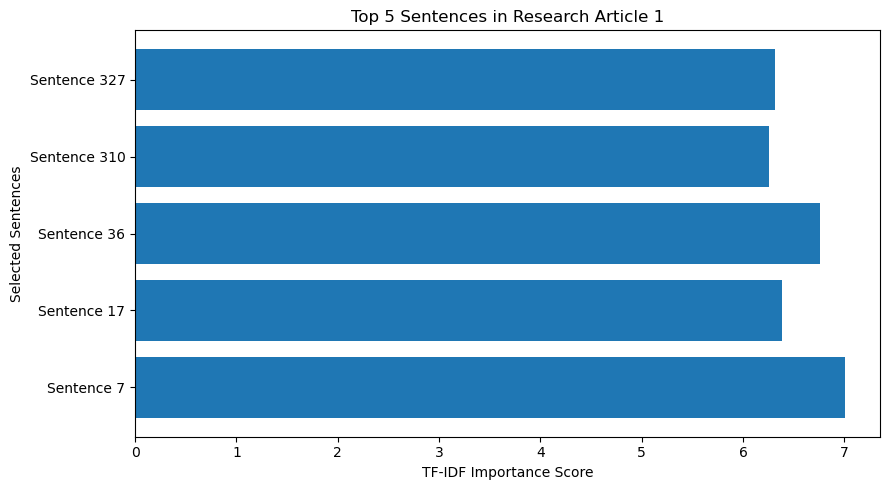

In [29]:
#Now for a visualisation - I have chosen a bar graph
selected_scores = [scores[i] for i in top_sentences]
sentence_labels = [f"Sentence {i+1}" for i in top_sentences]

plt.figure(figsize=(9, 5))
plt.barh(sentence_labels, selected_scores)
plt.xlabel("TF-IDF Importance Score")
plt.ylabel("Selected Sentences")
plt.title("Top 5 Sentences in Research Article 1")
plt.tight_layout()

plt.show()

As per the above results, sentence 7 scored the highest TF-IDF importance of 7, while sentence 310 scored the lowest. The higher the TF-IDF score, the more the sentence contains highly weighted words and of course the lowesr TF-IDF score means that sentence has the lowest weighted terms. However, the preprocessed denoising content will be used in the later LDA question as LDA does not require completed sentences to work optimally.

In [20]:
#Question 3.4) I have chosen to use Centroid-Based Extractive Summarization.
#This is also a straighforward and common summarization technique for summarising many documents. It will also work well to identify vocab

remaining_article = df[df["Article"] != "research_1.txt"]

sentences = []

for article in remaining_article["Content"]:
    doc = nlp(article)

    for sent in doc.sents:
        if len(sent.text.split()) >= 5:
            sentences.append(sent.text.strip())
print("Total Sentences:", len(sentences))

Total Sentences: 569


There are 569 sentences altogther in the remaining 4 articles. I also used the original Content to preserve sentence redability

In [30]:
count_vectorizer = CountVectorizer(stop_words="english")
matrix = count_vectorizer.fit_transform(sentences)
random_state=42

centroid = matrix.mean(axis=0).A

scores = cosine_similarity(matrix, centroid).ravel()

top_article_sentences = scores.argsort()[-8:]
top_article_sentences = sorted(top_article_sentences)

aggregate_summary = " ".join(sentences[i] for i in top_article_sentences)

print("Aggregate Summary:\n")
print(aggregate_summary)

Aggregate Summary:

The purposes of this chapter are to
 explore the nature and background of developmental research;
 describe the major types of developmental research by examining a range of representative projects;
 analyze the methodological approaches used in the various
types of developmental research;
 describe the issues, findings, and trends in recent developmental research; and
 discuss the future of this type of research in our field. While instructional development typically builds on previous research, developmental research attempts to produce the
models and principles that guide the design, development, and
evaluation processes. Note that these are portrayed as
types of research, rather than applications of research, and they
are all encompassed within the framework of developmental
research. While results from research in these areas impact the development process, the study of variables embedded in such
topics does not constitute developmental research. Keywords:

What does each code above do?
CountVectorizer converts the sentences into numerical word-frequency representations. Centroid is used to represent the average vocab profile of the combined articles. The cosine similarity metric measures how closely each sentence matches the overall contnent.

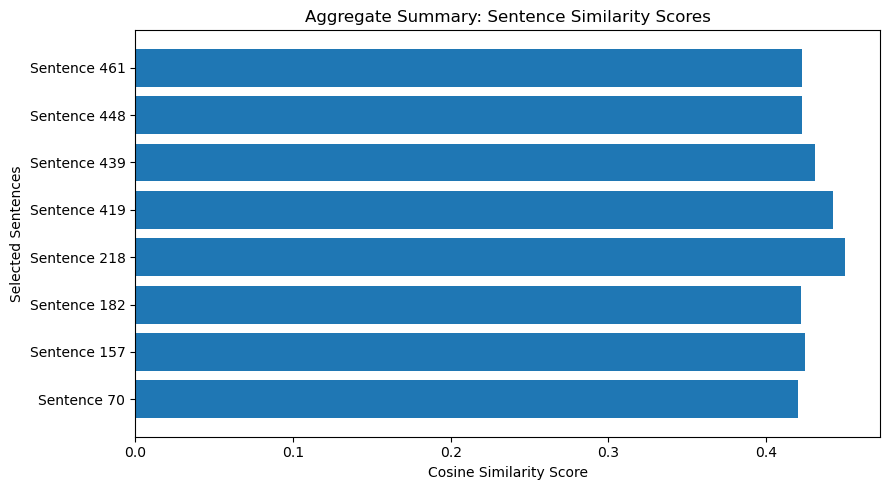

In [33]:
#Now for visualisation

selected_scores = [scores[i] for i in top_article_sentences]
labels = [f"Sentence {i+1}" for i in top_article_sentences]

plt.figure(figsize=(9, 5))
plt.barh(labels, selected_scores)
plt.xlabel("Cosine Similarity Score")
plt.ylabel("Selected Sentences")
plt.title("Aggregate Summary: Sentence Similarity Scores")
plt.tight_layout()

plt.show()

As per the above results, sentence 218 scored the highest cosine score at around 0.45. This can be interpreted as the content within this sentence have nearly identical meaning, shares close synonyms, and/or may discuss the exact same topic. Across all other sentences, there is a tightly clustered score between 0.41 to 0.45 which can imply that the summary is balanced and holds approximately the same content weights.

In [59]:
#Question 4.1) LDA model with 2 topics, list of words, and visualisation

#Application of LDA to all 5 articles
article_vectorizer = CountVectorizer(stop_words="english")
document_term_matrix = article_vectorizer.fit_transform(df["Processed_Content"])

lda = LatentDirichletAllocation(n_components=3, random_state=42)
topic_distribution = lda.fit_transform(document_term_matrix)

The CountVectorizer converts each article into numerical word counts while the lda discovers the three groups of related work. And the fit_transform calculates the topic distribution of every article

In [60]:
#Now to retrive the top 10 words for each topic

words = article_vectorizer.get_feature_names_out()

for i, topic in enumerate(lda.components_):
    top_words = topic.argsort()[-10:][::-1]
    random_state=42

    print(f"Topic {i+1}:")
    print(", ".join(words[j] for j in top_words))
    print()

Topic 1:
alpha, cronbach, instrument, value, report, reliability, use, science, scale, study

Topic 2:
research, researcher, method, study, qualitative, design, datum, triangulation, development, use

Topic 3:
expectation, accuracy, welcome, active, course, attend, independent, access, desire, confidence



These are the common words within each article. I have sorted the top 10 most featured words. There is no Topic name assigned so I have named each topic as follows: Topic 1: Research Reliability and Measurment. Topic 2: Research Methodology. Topic 3: Learning Expectations and Confidence.

In [61]:
#Now to create a dataframe for the topics

topic_df = pd.DataFrame(
    topic_distribution,
    columns=["Topic 1", "Topic 2", "Topic 3"]
)

topic_df.insert(0, "Article", df["Article"].values)

display(topic_df)

,Article,Topic 1,Topic 2,Topic 3
0,research_1.txt,0.000122,0.999767,0.000111
1,research_2.txt,0.000284,0.999450,0.000265
2,research_3.txt,0.000187,0.999648,0.000165
3,research_4.txt,0.999781,0.000114,0.000105
4,research_5.txt,0.000168,0.999681,0.000151


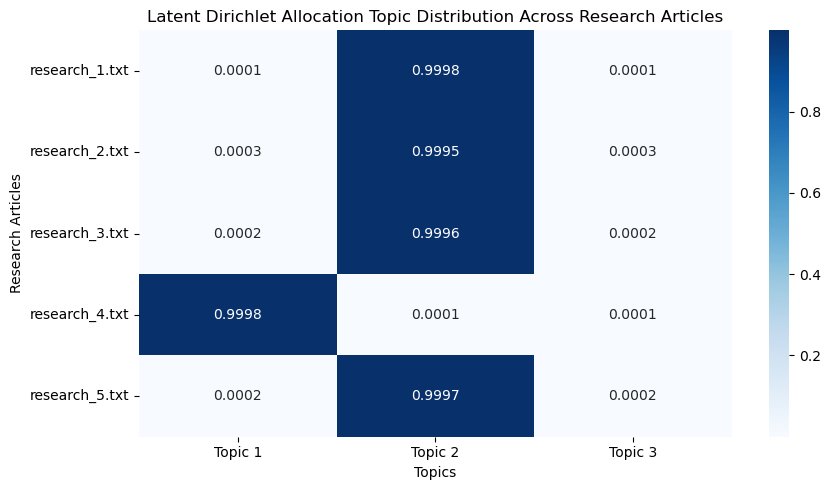

In [62]:
#A suitable visualisation...a heatmap!

plt.figure(figsize=(9, 5))

sns.heatmap(
    topic_df.set_index("Article"),
    annot=True,
    cmap="Blues",
    fmt=".4f"
)
plt.title("Latent Dirichlet Allocation Topic Distribution Across Research Articles")
plt.xlabel("Topics")
plt.ylabel("Research Articles")
plt.tight_layout()

plt.show()

There are plenty of insightful findings as per the results. I have chosen 3 topics - the LDA topic distribution revealed that Topic 2 was the most dominant topic within 4 out of the 5 articles, while Topic 1 dominated the fourth article respectively. Topic 3 displayed very small, almost negligible proportions across all five documents. These results can imply that the corpus may contain highly concentrated themes, although the small numbers of research articles may affect topic diversity and model stability. It is worthy to not a heatmap with almost 0 values is not a "bad" visualiation, instead it highlights how strongly model associates particular articles with particular topics.

In [69]:
#Question 4.2) pyLDAvis for the topics 1-3

topics = lda.components_ / lda.components_.sum(axis=1)[:, None]

lda_visual = pyLDAvis.prepare(
    topic_term_dists=topics,
    doc_topic_dists=topic_distribution,
    doc_lengths=np.asarray(document_term_matrix.sum(axis=1)).ravel(),
    vocab=article_vectorizer.get_feature_names_out(),
    term_frequency=np.asarray(document_term_matrix.sum(axis=0)).ravel(),
    R=10,
    sort_topics=False
)

In [71]:
pyLDAvis.display(lda_visual)

Topic 3 is very tiny! But this is expected due to the findings in the LDA analysis. The Intertopic Distance Map revealed that both Topic 1 and 2 were more prevalant across the research articles, wheras Topic 3 displayed minimal representation. This means that the corpus is primarily suited towards Research Reliability and Research Methodology rather than Learning Expectations and Confidence, which has contibuted very little to the overall topic distributions.